In [ ]:
!pip install -q datasets pandas scikit-learn tqdm huggingface_hub

In [ ]:
from datasets import load_dataset, concatenate_datasets
import pandas as pd

ds = load_dataset("dinushiTJ/nz_research_commons_classification")

train_ds = ds["train"]
test_ds = ds["test"]

full_ds = concatenate_datasets([train_ds, test_ds])
print(full_ds)


Dataset({
    features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence', 'embedding_text', 'embedding_token_count'],
    num_rows: 16589
})


In [ ]:
df = full_ds.to_pandas()

# convert int labels → string labels
label_names = full_ds.features["classification_label"].int2str

df["label_text"] = df["classification_label"].apply(label_names)

df = df[["embedding_text", "label_text"]]

# drop nulls
df = df.dropna()

In [ ]:
df = df.drop_duplicates(subset=["embedding_text"]).reset_index(drop=True)

print("Dataset size after dedup:", len(df))
print(df["label_text"].value_counts())

Dataset size after dedup: 16589
label_text
non_maori_origin    14753
maori_origin         1836
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label_text"]
)

print(len(train_df), len(test_df))

13271 3318


In [ ]:
import random
from tqdm import tqdm

def build_triplets(df, num_triplets_per_sample=2):
    triplets = []

    grouped = df.groupby("label_text")

    label_to_texts = {
        label: group["embedding_text"].tolist()
        for label, group in grouped
    }

    all_labels = list(label_to_texts.keys())

    for label in tqdm(all_labels):
        positives_pool = label_to_texts[label]
        negatives_pool = [
            txt for l in all_labels if l != label
            for txt in label_to_texts[l]
        ]

        if len(positives_pool) < 2:
            continue

        for anchor in positives_pool:
            for _ in range(num_triplets_per_sample):

                # positive (same class)
                positive = anchor
                while positive == anchor:
                    positive = random.choice(positives_pool)

                # negative (different class)
                negative = random.choice(negatives_pool)

                triplets.append({
                    "anchor": anchor,
                    "positive": positive,
                    "negative": negative,
                    "label": label
                })

    return pd.DataFrame(triplets)

In [ ]:
train_triplets = build_triplets(train_df, num_triplets_per_sample=2)
test_triplets = build_triplets(test_df, num_triplets_per_sample=1)

print(len(train_triplets), len(test_triplets))

100%|██████████| 2/2 [00:00<00:00, 57.42it/s]

26542 3318


In [ ]:
train_triplets = train_triplets.drop_duplicates().reset_index(drop=True)
test_triplets = test_triplets.drop_duplicates().reset_index(drop=True)

In [ ]:
from datasets import Dataset, DatasetDict

train_hf = Dataset.from_pandas(train_triplets)
test_hf = Dataset.from_pandas(test_triplets)

print(train_hf, test_hf)

Dataset({
    features: ['anchor', 'positive', 'negative', 'label'],
    num_rows: 26542
}) Dataset({
    features: ['anchor', 'positive', 'negative', 'label'],
    num_rows: 3318
})


In [ ]:
from google.colab import userdata
DUSH_HFT = userdata.get('DUSH_HFT')

In [ ]:
from huggingface_hub import login

login(token=DUSH_HFT)

In [ ]:
repo_name = "dinushiTJ/nz_research_commons_embedding_triplets"

dataset_dict = DatasetDict({
    "train": train_hf,
    "test": test_hf
})

In [ ]:
print(dataset_dict)
print(dataset_dict["train"].num_rows)
print(dataset_dict["test"].num_rows)

DatasetDict({
    train: Dataset({
        features: ['anchor', 'positive', 'negative', 'label'],
        num_rows: 26542
    })
    test: Dataset({
        features: ['anchor', 'positive', 'negative', 'label'],
        num_rows: 3318
    })
})
26542
3318


In [ ]:
dataset_dict["train"].push_to_hub(
    repo_name,
    split="train"
)

dataset_dict["test"].push_to_hub(
    repo_name,
    split="test"
)

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/27 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              : 100%|##########| 68.7MB / 68.7MB            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              : 100%|##########| 9.27MB / 9.27MB            

README.md:   0%|          | 0.00/491 [00:00<?, ?B/s]

CommitInfo(commit_url='https://huggingface.co/datasets/dinushiTJ/nz_research_commons_embedding_triplets/commit/365bfa4aaef310732ed974634c7c364b53d314ee', commit_message='Upload dataset', commit_description='', oid='365bfa4aaef310732ed974634c7c364b53d314ee', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/dinushiTJ/nz_research_commons_embedding_triplets', endpoint='https://huggingface.co', repo_type='dataset', repo_id='dinushiTJ/nz_research_commons_embedding_triplets'), pr_revision=None, pr_num=None)

In [ ]:
from huggingface_hub import HfApi

api = HfApi()

readme = """
---
license: mit
datasets:
- nz-embedding-triplet
---

# NZ Embedding Triplet Dataset

This dataset contains triplets for embedding fine-tuning:
- anchor
- positive (same class)
- negative (different class)

Used for training embedding models like EmbeddingGemma.
"""

api.upload_file(
    path_or_fileobj=readme.encode(),
    path_in_repo="README.md",
    repo_id=repo_name,
    repo_type="dataset"
)

CommitInfo(commit_url='https://huggingface.co/datasets/dinushiTJ/nz_research_commons_embedding_triplets/commit/01fc4cb7937fbce6a358f851ad5df5c22403ff33', commit_message='Upload README.md with huggingface_hub', commit_description='', oid='01fc4cb7937fbce6a358f851ad5df5c22403ff33', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/dinushiTJ/nz_research_commons_embedding_triplets', endpoint='https://huggingface.co', repo_type='dataset', repo_id='dinushiTJ/nz_research_commons_embedding_triplets'), pr_revision=None, pr_num=None)

In [ ]:
from datasets import load_dataset

ds_n = load_dataset(repo_name)
print(ds_n)

README.md:   0%|          | 0.00/265 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/68.7M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/9.27M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['anchor', 'positive', 'negative', 'label'],
        num_rows: 26542
    })
    test: Dataset({
        features: ['anchor', 'positive', 'negative', 'label'],
        num_rows: 3318
    })
})


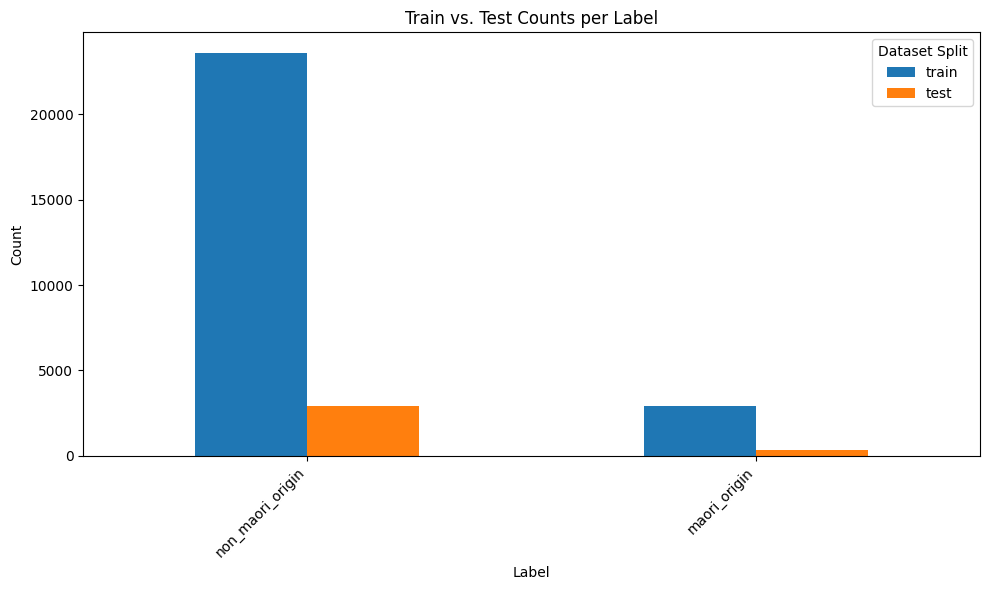

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Get label counts for train and test datasets
train_label_counts = pd.Series(dataset_dict["train"]["label"]).value_counts()
test_label_counts = pd.Series(dataset_dict["test"]["label"]).value_counts()

# Combine into a single DataFrame for plotting
combined_counts_df = pd.DataFrame({
    'train': train_label_counts,
    'test': test_label_counts
}).fillna(0)

# Sort by total count for better visualization
combined_counts_df['total'] = combined_counts_df['train'] + combined_counts_df['test']
combined_counts_df = combined_counts_df.sort_values('total', ascending=False).drop(columns=['total'])

# Plotting
combined_counts_df.plot(kind='bar', figsize=(10, 6))
plt.title('Train vs. Test Counts per Label')
plt.xlabel('Label')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Dataset Split')
plt.tight_layout()
plt.show()